# 06 · Primer clustering con DBSCAN (issue #14 · ML-02)

**Objetivo:** probar DBSCAN con las mismas 4 variables y la misma preparación que K-Means (`05`), para ver si encuentra grupos de forma libre y detectar municipios atípicos.

**Cómo funciona DBSCAN, en corto:** no pide el número de grupos. Un grupo es una zona densa de municipios parecidos. Hay dos parámetros:
- `eps`: radio que define "estar cerca".
- `min_samples`: mínimo de vecinos dentro de ese radio para formar una zona densa.

Los municipios que no caen en ninguna zona densa se marcan como **ruido** (`-1`): son los atípicos.

Este notebook va **separado** del de K-Means (`05`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEMILLA = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'notebooks').is_dir())
DATA = ROOT / 'data/processed/sitewise_v03'
SALIDA = ROOT / 'data/processed/sitewise_ml'
assert (DATA / 'dataset_municipal.csv').exists(), 'Genera antes el dataset con los notebooks 01, 02 y 03'
pd.set_option('display.width', 200)
print('Datos en:', DATA.relative_to(ROOT))

Datos en: data\processed\sitewise_v03


## 1. Cargar las 4 variables

In [2]:
VARIABLES = [
    'poblacion_2025',
    'suelo_industrial_cartografiado_pct',
    'dist_recta_eje_autovia_km',
    'dist_recta_ttm_km',
]
ETIQUETAS = ['cod_ine', 'nombre', 'provincia', 'ccaa']

df = pd.read_csv(DATA / 'dataset_municipal.csv', dtype={'cod_ine': str}, usecols=ETIQUETAS + VARIABLES)
assert df['cod_ine'].is_unique and len(df) == 8132
X = df[VARIABLES].copy()

print('Municipios:', len(df))
print('Huecos por variable:')
print(X.isna().sum().to_string())

Municipios: 8132
Huecos por variable:
poblacion_2025                          0
suelo_industrial_cartografiado_pct      0
dist_recta_eje_autovia_km              56
dist_recta_ttm_km                     161


## 2. Huecos

In [3]:
# Las distancias sin dato (islas y 6 casos peninsulares) se rellenan con la distancia máxima observada.
# Este valor se usa SOLO para entrenar: la app mostrará siempre el dato observado y su estado.
sin_dato = X.isna()
X_ent = X.copy()
for c in ['dist_recta_eje_autovia_km', 'dist_recta_ttm_km']:
    X_ent[c] = X_ent[c].fillna(X_ent[c].max())

# El 0 de suelo industrial significa "sin polígonos en el catálogo", no "no hay suelo": no se toca.
print('Municipios con algún hueco rellenado:', int(sin_dato.any(axis=1).sum()))
print('Suelo industrial = 0:', f"{(X['suelo_industrial_cartografiado_pct'] == 0).mean():.1%}")

Municipios con algún hueco rellenado: 161
Suelo industrial = 0: 54.5%


## 3. Transformar: log y recorte

Igual que en `05`: log(1 + x) y recorte a los percentiles 1-99.

                                    antes  despues_log1p
poblacion_2025                      48.26           0.46
suelo_industrial_cartografiado_pct   7.89           2.87
dist_recta_eje_autovia_km            2.14          -0.27
dist_recta_ttm_km                    1.09          -0.77


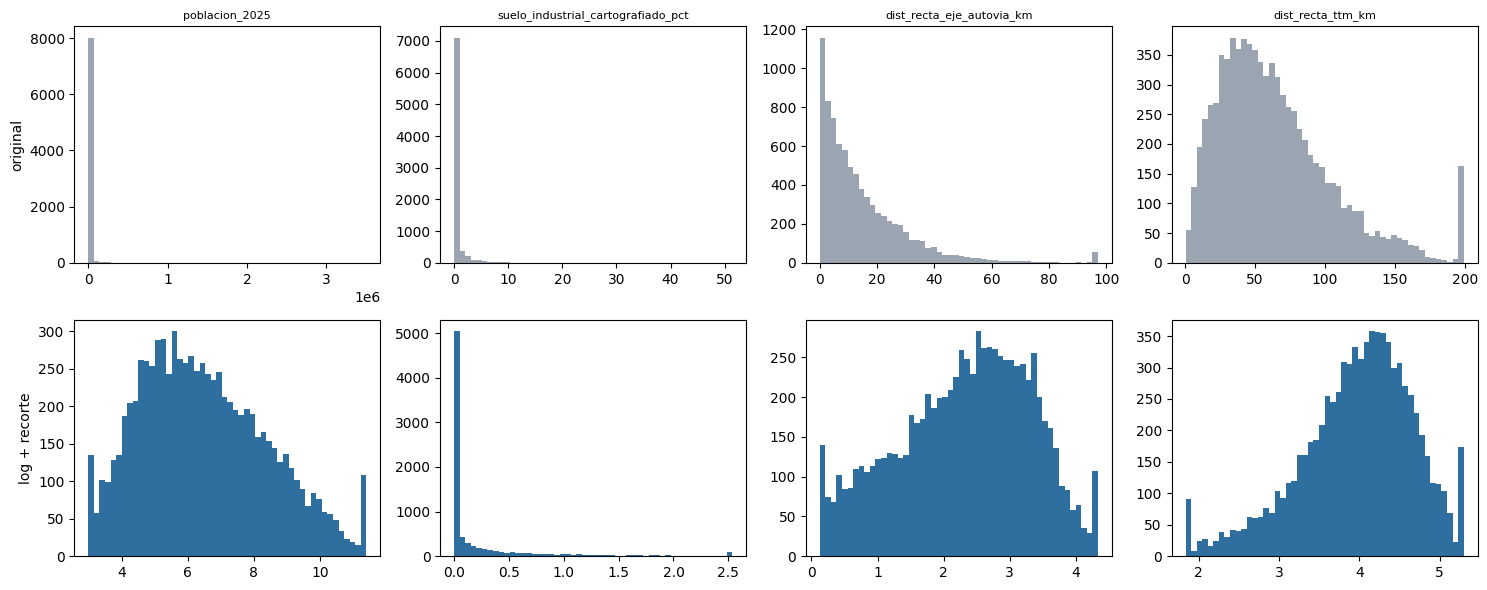

In [4]:
# Asimetría (skew) antes y después del log(1 + x). Un valor cercano a 0 es una distribución simétrica.
X_log = np.log1p(X_ent)
asimetria = pd.DataFrame({'antes': X_ent.skew(), 'despues_log1p': X_log.skew()}).round(2)
print(asimetria.to_string())

# Recorte a los percentiles 1-99 para que unos pocos municipios extremos no dominen la escala.
p1, p99 = X_log.quantile(0.01), X_log.quantile(0.99)
X_rec = X_log.clip(lower=p1, upper=p99, axis=1)

fig, ejes = plt.subplots(2, 4, figsize=(15, 6))
for j, c in enumerate(VARIABLES):
    ejes[0, j].hist(X_ent[c], bins=50, color='#9aa5b1'); ejes[0, j].set_title(c, fontsize=8)
    ejes[1, j].hist(X_rec[c], bins=50, color='#2f6f9f')
ejes[0, 0].set_ylabel('original'); ejes[1, 0].set_ylabel('log + recorte')
plt.tight_layout(); plt.show()

## 4. Escalar y reducir con PCA

Igual que en `05`, para que los resultados de ambos métodos se puedan comparar.

In [5]:
escalador = StandardScaler()
Z = pd.DataFrame(escalador.fit_transform(X_rec), columns=VARIABLES, index=df.index)
print('Media ~0 y desviación 1 tras escalar:')
print(Z.agg(['mean', 'std']).round(3).to_string())

# PCA: componentes necesarios para explicar al menos el 85 % de la varianza (requisito del enunciado).
pca = PCA(n_components=0.85, random_state=SEMILLA)
Zp = pca.fit_transform(Z)
print('Componentes:', pca.n_components_, '| varianza explicada:', pca.explained_variance_ratio_.round(3), '| acumulada:', pca.explained_variance_ratio_.sum().round(3))
print()
print('Peso de cada variable en cada componente:')
print(pd.DataFrame(pca.components_.T, index=VARIABLES, columns=[f'PC{i+1}' for i in range(pca.n_components_)]).round(2).to_string())

Media ~0 y desviación 1 tras escalar:
      poblacion_2025  suelo_industrial_cartografiado_pct  dist_recta_eje_autovia_km  dist_recta_ttm_km
mean            -0.0                                -0.0                        0.0                0.0
std              1.0                                 1.0                        1.0                1.0
Componentes: 3 | varianza explicada: [0.554 0.185 0.153] | acumulada: 0.892

Peso de cada variable en cada componente:
                                     PC1   PC2   PC3
poblacion_2025                      0.51  0.59  0.12
suelo_industrial_cartografiado_pct  0.54  0.35 -0.07
dist_recta_eje_autovia_km          -0.48  0.47  0.71
dist_recta_ttm_km                  -0.47  0.56 -0.69


## 5. Elegir `eps`: gráfico de k-distancias

Para cada municipio se mide la distancia a su vecino número `min_samples`. Se ordenan de menor a mayor: donde la curva sube de golpe están los municipios aislados, y esa zona orienta el valor de `eps`.

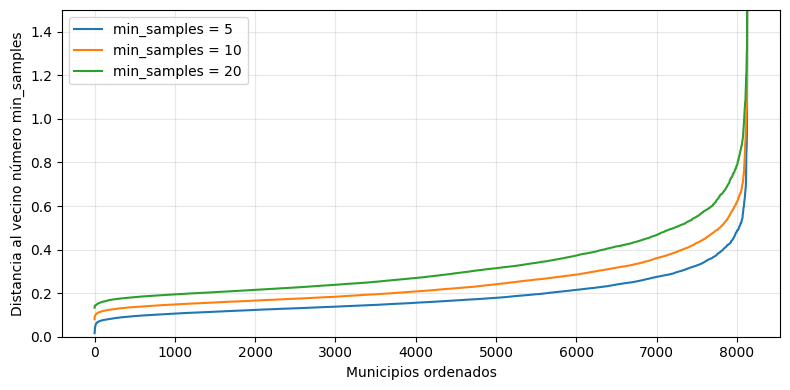

In [6]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

fig, ax = plt.subplots(figsize=(8, 4))
for ms in (5, 10, 20):
    dist, _ = NearestNeighbors(n_neighbors=ms).fit(Zp).kneighbors(Zp)
    ax.plot(np.sort(dist[:, -1]), label=f'min_samples = {ms}')
ax.set_ylim(0, 1.5); ax.set_xlabel('Municipios ordenados'); ax.set_ylabel('Distancia al vecino número min_samples')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 6. Probar combinaciones de `eps` y `min_samples`

In [7]:
filas = []
for ms in (5, 10, 20):
    for eps in (0.2, 0.3, 0.4, 0.5, 0.6, 0.8):
        etiquetas = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zp)
        n_grupos = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        dentro = etiquetas != -1
        tamanos = sorted(np.bincount(etiquetas[dentro]), reverse=True) if n_grupos else []
        filas.append({
            'min_samples': ms, 'eps': eps, 'grupos': n_grupos,
            '% ruido': round((~dentro).mean() * 100, 1),
            '% en el grupo mayor': round(tamanos[0] / len(etiquetas) * 100, 1) if n_grupos else 0,
            'silhouette (sin ruido)': round(silhouette_score(Zp[dentro], etiquetas[dentro]), 3) if n_grupos >= 2 else np.nan,
        })
rejilla = pd.DataFrame(filas)
rejilla

,min_samples,eps,grupos,% ruido,% en el grupo mayor,silhouette (sin ruido)
0,5,0.2,69,21.3,71.9,-0.283
1,5,0.3,19,6.0,90.4,0.036
2,5,0.4,9,1.8,97.2,0.026
3,5,0.5,2,0.5,99.5,0.427
4,5,0.6,1,0.2,99.8,NaN
5,5,0.8,1,0.0,100.0,NaN
6,10,0.2,22,40.2,56.4,-0.244
7,10,0.3,10,14.0,84.0,0.028
8,10,0.4,3,4.4,94.8,0.191
9,10,0.5,1,1.4,98.6,NaN


## 7. Lectura de la rejilla

Se observa lo mismo en casi todas las combinaciones: **un grupo enorme que contiene a casi todos los municipios, y unos pocos grupos diminutos o ruido**.

- Con `eps` pequeño, el algoritmo rompe los datos en muchos grupos pequeños y marca como ruido a una parte grande.
- Con `eps` grande, todo se junta en un único grupo.
- No hay un punto intermedio con varios grupos grandes y equilibrados.

Esto confirma lo que ya dijo K-Means (Silhouette ~0,28): **los municipios forman un continuo, no islas separadas**, y DBSCAN, que busca islas de densidad, no puede repartirlos en perfiles útiles.

Aun así, DBSCAN sirve para otra cosa: **detectar municipios atípicos**. Se elige `min_samples = 10` y `eps = 0.4` (zona de subida de la curva de k-distancias; deja pocos grupos y un ruido pequeño).

In [8]:
EPS, MIN_SAMPLES = 0.4, 10
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Zp)
df['dbscan'] = db.labels_
print(df['dbscan'].value_counts().sort_index().to_string())
print('Ruido:', f"{(df['dbscan'] == -1).mean():.1%}")

dbscan
-1     360
 0    7712
 1      51
 2       9
Ruido: 4.4%


## 8. Perfil de los grupos y del ruido

Mediana de cada variable en unidades originales. La fila `-1` son los municipios atípicos.

In [9]:
def perfil(df, etiqueta):
    """Mediana de cada variable (en unidades originales), tamaño y % de municipios por grupo."""
    g = df.groupby(etiqueta)
    t = g[VARIABLES].median().round(2)
    t.insert(0, 'municipios', g.size())
    t.insert(1, '% del total', (g.size() / len(df) * 100).round(1))
    return t

perfil(df, 'dbscan')

,municipios,% del total,poblacion_2025,suelo_industrial_cartografiado_pct,dist_recta_eje_autovia_km,dist_recta_ttm_km
dbscan,,,,,,
-1,360,4.4,12908.5,2.46,2.18,16.02
0,7712,94.8,475.0,0.00,10.72,56.49
1,51,0.6,6459.0,0.03,NaN,NaN
2,9,0.1,19458.0,3.94,10.24,24.55


**Cómo leer esta tabla**

- **Ruido (-1):** no son municipios "raros" en el mal sentido. La mediana es de ~13.000 habitantes con suelo industrial: son sobre todo **ciudades grandes**, que quedan en la zona poco densa de los datos porque hay pocas parecidas.
- **Grupo 1 (51 municipios):** tiene la distancia a autovía y a ferrocarril vacía en esta tabla porque son **municipios con distancias rellenadas** (islas): al rellenar con el máximo observado quedan todos juntos y DBSCAN los ve como un grupo. Es un efecto del relleno y no un perfil real.
- **Grupo 0:** el resto, el 95 % de los municipios.

In [10]:
ruido = df[df['dbscan'] == -1]
print('Comunidades con más municipios atípicos:')
print(ruido['ccaa'].value_counts().head(8).to_string())
print()
print('Atípicos con alguna distancia rellenada:', int(sin_dato.loc[ruido.index].any(axis=1).sum()), 'de', len(ruido))
print()
print('Los 10 atípicos de mayor población:')
print(ruido.nlargest(10, 'poblacion_2025')[['nombre', 'provincia'] + VARIABLES].to_string(index=False))

Comunidades con más municipios atípicos:
ccaa
Cataluña                       64
Andalucía                      54
Castilla y León                53
Comunitat Valenciana           26
Canarias                       24
Navarra, Comunidad Foral de    18
Madrid, Comunidad de           17
País Vasco                     16

Atípicos con alguna distancia rellenada: 43 de 360

Los 10 atípicos de mayor población:
                     nombre              provincia  poblacion_2025  suelo_industrial_cartografiado_pct  dist_recta_eje_autovia_km  dist_recta_ttm_km
                    Sevilla                Sevilla        689423.0                           12.716248                   1.369996           2.036283
                      Palma          Illes Balears        434786.0                            3.258066                   2.568546                NaN
Palmas de Gran Canaria, Las             Las Palmas        381868.0                            1.578672                   5.320834                N

## 9. Comparar con K-Means

Si has ejecutado antes `05`, se cruzan los grupos de K-Means con los atípicos de DBSCAN.

In [11]:
ruta_km = SALIDA / 'clusters_kmeans_v01.csv'
if ruta_km.exists():
    km = pd.read_csv(ruta_km, dtype={'cod_ine': str})
    cruce = df[['cod_ine', 'dbscan']].merge(km, on='cod_ine', validate='one_to_one')
    print('Municipios de cada grupo de K-Means que DBSCAN marca como ruido (atípico):')
    print(pd.crosstab(cruce['grupo_kmeans'], cruce['dbscan'] == -1, margins=True).rename(columns={False: 'normal', True: 'atípico'}).to_string())
else:
    print('Ejecuta antes el notebook 05 para poder comparar.')

Municipios de cada grupo de K-Means que DBSCAN marca como ruido (atípico):
dbscan        normal  atípico   All
grupo_kmeans                       
1                412      164   576
2                978      113  1091
3               1647       60  1707
4               3115        5  3120
5               1620       18  1638
All             7772      360  8132


## 10. Guardar el resultado

In [12]:
SALIDA.mkdir(parents=True, exist_ok=True)
df[['cod_ine', 'dbscan']].rename(columns={'dbscan': 'grupo_dbscan'}).to_csv(SALIDA / 'clusters_dbscan_v01.csv', index=False)
print('Guardado en:', SALIDA.relative_to(ROOT))

Guardado en: data\processed\sitewise_ml


## Conclusiones y siguientes pasos

- DBSCAN no reparte los municipios en perfiles útiles: casi todos caen en un solo grupo. No es un fallo del método, sino una propiedad de los datos (un continuo).
- Como detector de atípicos marca un 4 % de municipios, pero son sobre todo **grandes ciudades** (zona poco densa), no errores de datos.
- Los grupos pequeños que aparecen son en buena parte un **efecto del relleno de distancias** en las islas: conviene tratarlos aparte en vez de forzarlos dentro del clustering.
- Recomendación para #14: usar **K-Means (`05`) como modelo de perfiles** y DBSCAN como complemento para señalar municipios atípicos.
- Pendiente: contrastarlo con Elena y registrar ambos experimentos en MLflow (#15).